In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.donnees import charger_arcep

arcep = charger_arcep()
print(arcep.shape)
arcep.dtypes

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(354282, 30)


acess_duration                       float64
bitrate_dl                           float64
bitrate_ul                           float64
date_start                               str
hour_start                               str
insee_com                                str
latitude_start                       float64
loaded_in_less_10_secondes           float64
loaded_in_less_5_secondes            float64
longitude_start                      float64
mcc_start                            float64
mnc_start                            float64
operator                                 str
quality_correct                      float64
quality_perfect                      float64
rscp                                 float64
rsrp                                 float64
rsrq                                 float64
protocole                                str
situation                                str
techno_start                             str
terminal                                 str
territory 

In [3]:
arcep.notna().mean().sort_values().round(3)

rscp                          0.019
bitrate_ul                    0.047
upload_ok                     0.047
quality_correct               0.048
quality_perfect               0.048
bitrate_dl                    0.094
transfert_file_size           0.188
loaded_in_less_5_secondes     0.715
loaded_in_less_10_secondes    0.715
mcc_start                     0.884
mnc_start                     0.884
url                           0.903
acess_duration                0.948
rsrp                          0.955
rsrq                          0.956
longitude_start               1.000
latitude_start                1.000
date_start                    1.000
insee_com                     1.000
hour_start                    1.000
operator                      1.000
techno_start                  1.000
situation                     1.000
protocole                     1.000
territory                     1.000
terminal                      1.000
zone                          1.000
zone_name                   

In [4]:
print(arcep["protocole"].value_counts(), "\n")
print(arcep["Result"].value_counts(), "\n")
pd.crosstab(arcep["protocole"], arcep["Result"], normalize="index").round(3)

protocole
WEB         253260
DOWNLOAD     33384
ICMP         17328
STREAM       16933
ULH          16695
UPLOAD       16682
Name: count, dtype: int64 

Result
Success         293386
Traffic Fail     37148
TimeOut          21040
Drop              2666
Setup Fail          42
Name: count, dtype: int64 



Result,Drop,Setup Fail,Success,TimeOut,Traffic Fail
protocole,,,,,
DOWNLOAD,0.007,0.000,0.400,0.000,0.593
ICMP,0.000,0.000,0.922,0.000,0.078
STREAM,0.000,0.002,0.902,0.031,0.064
ULH,0.011,0.000,0.898,0.000,0.091
UPLOAD,0.007,0.000,0.190,0.000,0.803
WEB,0.008,0.000,0.911,0.081,0.000


In [5]:
colonnes = ["bitrate_dl", "bitrate_ul", "acess_duration", "loaded_in_less_5_secondes", "quality_correct", "upload_ok", "rsrp"]
arcep.groupby("protocole")[colonnes].apply(lambda g: g.notna().mean()).round(2)

,bitrate_dl,bitrate_ul,acess_duration,loaded_in_less_5_secondes,quality_correct,upload_ok,rsrp
protocole,,,,,,,
DOWNLOAD,1.0,0.0,1.00,0.0,0.0,0.0,0.95
ICMP,0.0,0.0,0.00,0.0,0.0,0.0,0.96
STREAM,0.0,0.0,0.94,0.0,1.0,0.0,0.96
ULH,0.0,0.0,1.00,0.0,0.0,1.0,0.92
UPLOAD,0.0,1.0,1.00,0.0,0.0,0.0,0.95
WEB,0.0,0.0,1.00,1.0,0.0,0.0,0.96


In [6]:
PROTOCOLES_SERVICE = ["WEB", "ICMP", "STREAM", "ULH"]

tests = arcep[arcep["protocole"].isin(PROTOCOLES_SERVICE)].copy()
tests["echec"] = (tests["Result"] != "Success").astype(int)

print(tests.shape)
print(f"Taux d'échec global : {tests['echec'].mean():.1%}")

(304216, 31)
Taux d'échec global : 9.0%


In [7]:
for facteur in ["protocole", "operator", "zone", "situation"]:
    print(tests.groupby(facteur)["echec"].mean().sort_values().round(3), "\n")

protocole
ICMP      0.078
WEB       0.089
STREAM    0.098
ULH       0.102
Name: echec, dtype: float64 

operator
Orange      0.065
Bouygues    0.090
SFR         0.091
Free        0.113
Name: echec, dtype: float64 

zone
Zones denses            0.049
Zones intermediaires    0.051
Zones touristiques      0.090
Zones rurales           0.164
Name: echec, dtype: float64 

situation
Outdoor    0.066
Incar      0.076
Indoor     0.124
Name: echec, dtype: float64 



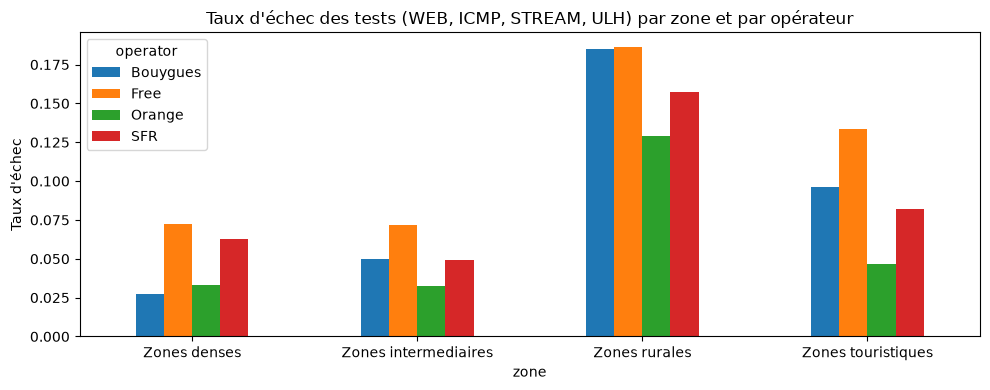

In [8]:
tableau = tests.pivot_table(index="zone", columns="operator", values="echec", aggfunc="mean")
ax = tableau.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_ylabel("Taux d'échec")
ax.set_title("Taux d'échec des tests (WEB, ICMP, STREAM, ULH) par zone et par opérateur")
plt.tight_layout()
plt.savefig("../results/figures/arcep_echec_zone_operateur.png", dpi=150)
plt.show()

In [9]:
bornes = [-150, -120, -110, -100, -90, -80, -40]
tests["tranche_rsrp"] = pd.cut(tests["rsrp"], bins=bornes)

par_tranche = tests.groupby("tranche_rsrp", observed=True)["echec"].agg(["mean", "size"])
par_tranche.columns = ["taux_echec", "nb_tests"]
par_tranche.round(3)

,taux_echec,nb_tests
tranche_rsrp,,
"(-150, -120]",0.536,11181
"(-120, -110]",0.092,69328
"(-110, -100]",0.023,103911
"(-100, -90]",0.011,65442
"(-90, -80]",0.008,30954
"(-80, -40]",0.009,9927


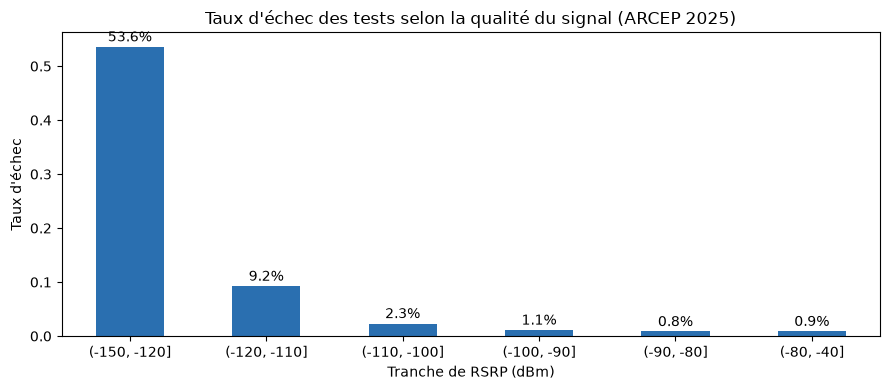

In [10]:
ax = par_tranche["taux_echec"].plot(kind="bar", figsize=(9, 4), rot=0, color="#2a6fb0")
ax.set_xlabel("Tranche de RSRP (dBm)")
ax.set_ylabel("Taux d'échec")
ax.set_title("Taux d'échec des tests selon la qualité du signal (ARCEP 2025)")
for i, v in enumerate(par_tranche["taux_echec"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.savefig("../results/figures/arcep_echec_rsrp.png", dpi=150)
plt.show()

In [11]:
bon_signal = tests[tests["rsrp"] > -90]
suspects = bon_signal[bon_signal["echec"] == 1]

print(f"Tests avec RSRP > -90 dBm : {len(bon_signal)}")
print(f"Échecs malgré ce bon signal : {len(suspects)} ({len(suspects) / len(bon_signal):.1%})")
suspects["Result"].value_counts()

Tests avec RSRP > -90 dBm : 40881
Échecs malgré ce bon signal : 348 (0.9%)


Result
TimeOut         235
Traffic Fail    104
Drop              8
Setup Fail        1
Name: count, dtype: int64

In [12]:
tests["creneau"] = tests["instant"].dt.floor("10s")
tests["lat"] = tests["latitude_start"].round(3)
tests["lon"] = tests["longitude_start"].round(3)
CLE = ["creneau", "lat", "lon", "protocole"]

groupes = tests.groupby(CLE)
tests["nb_operateurs"] = groupes["operator"].transform("nunique")
tests["nb_echecs"] = groupes["echec"].transform("sum")

quatre = tests[tests["nb_operateurs"] == 4]
print("Groupes complets (4 opérateurs) :", quatre.groupby(CLE).ngroups)
quatre.groupby(CLE)["echec"].sum().value_counts().sort_index()

Groupes complets (4 opérateurs) : 43329


echec
0    37313
1     3361
2     1141
3      754
4      760
Name: count, dtype: int64

In [13]:
isoles = quatre[(quatre["echec"] == 1) & (quatre["nb_echecs"] == 1)]
print("Échecs isolés (1 seul opérateur sur 4) :", len(isoles))
print(isoles["operator"].value_counts(), "\n")
print("RSRP médian des échecs isolés :", isoles["rsrp"].median(), "dBm")
print("RSRP médian de tous les tests  :", quatre["rsrp"].median(), "dBm")
print(f"Échecs isolés avec RSRP > -100 dBm : {(isoles['rsrp'] > -100).mean():.1%}")

Échecs isolés (1 seul opérateur sur 4) : 3361
operator
Free        1540
SFR          696
Bouygues     572
Orange       553
Name: count, dtype: int64 

RSRP médian des échecs isolés : -115.0 dBm
RSRP médian de tous les tests  : -102.77 dBm
Échecs isolés avec RSRP > -100 dBm : 7.4%
